# **Wastewater at a Crossroads: Is Treatment Keeping Pace with Generation?**

## Performance Innovative Task (PIT) — Midterm Lab Exam Report

---

### **Project Metadata**
* **Course & Section:** DS311 — Exploratory Data Analysis (Sections DS3A | DS3B)
* **Assigned Domain:** **Group 4 — Environment and Nature**
* **Group Members & Roles:**
  1. `Rusjane Gerongay` — *Role / Contribution (e.g., Lead Analyst / Domain Modeling)*
  2. `Gene` — *Role / Contribution (e.g., Data Cleaning & Preprocessing)*
  3. `Den Penano` — *Role / Contribution (e.g., Univariate & Bivariate EDA)*
  4. `Rafael` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*
  5. `Rogelio Mandamian` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*
  6. `Rodney Trillo` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*
  7. `Johann Megalbio` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*
  8. `Eleah Jaizel T. Cabili` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*
  9. `Kirsten Roise G. Moog` — *Role / Contribution (e.g., Business Synthesis & Poster Design)*

---

## 1. Executive Summary & Business Problem Formulation

### 1.1 Domain Background (Environment and Nature)
Provide a concise overview of the environmental challenge being explored. Explain the macro context (e.g., global urbanization, water resource depletion, municipal utility burdens, industrial expansion) and why monitoring this environmental indicator is essential for long-term sustainability.

> *Rapid population growth, urbanization, and industrial expansion are increasing the volume of wastewater that countries must collect and treat. When this wastewater is released untreated, it contaminates rivers, groundwater, and coastal ecosystems. It also spreads waterborne disease and degrades the freshwater supply that cities, farms, and industries depend on. For this reason, wastewater treatment is treated as a core part of sustainable development. It is addressed directly in the UN Sustainable Development Goal 6 (Clean Water and Sanitation), which calls for halving the proportion of untreated wastewater by 2030.*

> *Treatment infrastructure, however, is capital-intensive and slow to build. Plants take years to plan, finance, and commission, while wastewater volumes grow continuously with population and economic activity. Where treatment capacity lags generation, the gap shows up as untreated discharge, which means environmental damage, public-health costs, and regulatory exposure. Countries also differ widely in how much wastewater they generate and how much of it they actually process. A single national average therefore hides large disparities between reporting jurisdictions.*

>*This study analyses cross-national UN environmental statistics to examine how the volume of wastewater generated relates to the volume treated in urban treatment plants. Monitoring this relationship matters for long-term sustainability because it shows whether treatment capacity is keeping pace with the workload placed on it, or whether a structural deficit is emerging that calls for investment and policy action.*

---

### 1.2 The Business Question
State the exact, formal **business question** that guides this study. The question must connect environmental indicators directly to operational decision-making, capital expenditure (CAPEX), private-public partnerships (PPPs), regulatory compliance, or enterprise ESG strategy.

> **Formal Business Question:**  
> *"As municipal wastewater generation grows due to rapid urban expansion, does urban treatment plant capacity scale at parity, or does an escalating
infrastructure deficit emerge that justifies private capital expenditure (CAPEX) and Public-Private Partnerships (PPPs) in wastewater utility
facilities?"*

---
**Why this is a business question?**
> *Wastewater plants are capital-intensive assets that take years to finance, build, and commission. Investors and utility operators must therefore decide **where** and **how much** to build before the shortfall becomes visible. The question links an environmental indicator (volume of wastewater generated) to three operational decisions: CAPEX allocation, PPP structuring, and regulatory and ESG compliance planning.*

**Operational definitions used in this study:**
* **Workload ($X$):** Total wastewater generated, `total_wastewater_generated_1k_m3_day` (1,000 m³/day).
* **Capacity ($Y$):** Wastewater treated in urban plants, `urban_wastewater_treated_1k_m3_day` (1,000 m³/day).
* **Parity:** Treatment keeps pace with generation. In regression terms, the slope of $Y$ on $X$ is close to 1, so each extra 1,000 m³/day generated is matched by about 1,000 m³/day of extra treatment.
* **Deficit:** Treatment grows more slowly than generation (slope below 1), so the untreated gap ($X - Y$) widens as national scale increases.

**Sub-questions answered in Sections 3 to 5:**
1. What does a typical country generate and treat, and how unequal is the distribution? (Section 3)
2. Do countries that generate more wastewater also treat more in urban plants, and how strongly? (Section 4.2)
3. How many additional units of treatment accompany each additional unit generated? (Section 4.3)
4. Is the relationship statistically significant at $\alpha = 0.05$? (Section 4.4)

**Scope note.** *The data is a cross-section of 24 countries, each at its latest reporting year (2000 to 2017). The study therefore measures how treatment *scales across countries of different size*, not how one country's capacity changes over time. $Y$ covers urban plants only, so the deficit it implies is an upper bound for countries that also treat through other plants or independent facilities.*

---
### 1.3 Strategic Relevance & Stakeholder Impact
Identify the key stakeholders who benefit from this analysis and how the findings inform decision-making:
* **Infrastructure Investors & Utility Operators:** Where should capital be allocated to alleviate capacity bottlenecks?
* **Municipal Policymakers & Regulatory Agencies:** What regulatory thresholds, tariffs, or environmental mandates are needed?
* **Corporate ESG Planners & Supply Chain Managers:** How does this resource stress translate into business operational risks?

| Stakeholder | Decision the analysis informs | How the findings are used |
| :--- | :--- | :--- |
| **Infrastructure Investors & Utility Operators** | Where to allocate CAPEX to relieve capacity bottlenecks | The regression slope and the gap between $X$ and $Y$ show how much treatment capacity is added per unit of wastewater generated. A slope well below 1 signals an investable capacity shortfall. |
| **Municipal Policymakers & Regulatory Agencies** | Which treatment mandates, tariffs, or PPP frameworks to set | The spread of $Y$ across countries (Section 3) shows how far typical performance sits from the best performers. This helps set realistic compliance thresholds aligned with SDG 6. |
| **Corporate ESG Planners & Supply Chain Managers** | How to audit environmental and operational risk in sourcing locations | Countries or jurisdictions where treatment lags generation carry higher water-quality, regulatory, and reputational risk for facilities and suppliers located there. |

The same results serve all three groups. Investors use them to size the opportunity, regulators to justify intervention, and corporations to screen exposure.

---

### 1.4 Primary Objectives & Hypotheses
1. **Objective 1 (Univariate Exploration):** Quantify the central tendency, dispersion, distribution shape, and extreme outliers of the primary driver ( X , total wastewater generated) and the response ( Y , urban wastewater treated), using the 24 complete-case countries.
2. **Objective 2 (Bivariate Interaction):** Evaluate the correlation (Pearson $r$ and Spearman $\rho$), the linearity, and the rate of change (OLS regression slope) strictly between $X$ and $Y$, and compare that slope with the parity benchmark of 1.
3. **Objective 3 (Decision Translation):** Convert the statistical results into a direct answer to the business question and into CAPEX, PPP, and risk recommendations (Section 5).
4. **Hypothesis ($H_0$ vs $H_1$):**
   * **Null Hypothesis ($H_0$):** There is no significant relationship between total wastewater generated ($X$) and urban wastewater treated ($Y$) ($\rho = 0$).
   * **Alternative Hypothesis ($H_1$):** There is a statistically significant relationship between total wastewater generated ($X$) and urban wastewater treated ($Y$) ($\rho \neq 0$). A positive relationship is expected, since countries that generate more wastewater should operate more urban treatment capacity.
   * **Decision rule:** Test at $\alpha = 0.05$ using the two-sided $p$-value of the regression slope, which equals the Pearson correlation test. Reject $H_0$ if $p < 0.05$. Spearman's $\rho$ is reported as a robustness check because both variables are heavily right-skewed.

> *Note: rejecting $H_0$ shows that treatment and generation move together. It does not by itself show parity. Parity is judged separately from the size of the slope in Section 4.3.*

---


## 2. Dataset Architecture & Preprocessing Methodology

### 2.1 Dataset Provenance & Selection
* **Repository:** UN / Kaggle Global Environmental Indicators
* **Subcategory / File Selected:** `Inland Water Resources / Wastewater generation and treatment.csv`
* **Unit of Analysis:** Cross-national observations across sovereign states and territories.
* **Temporal Horizon:** Latest available reporting period across reporting nations.

---

### 2.2 Identification of the Two Numerical Variables
Per the DS311 PIT guidelines, **bivariate analysis is strictly limited to two numerical variables only**:

| Role | Variable Name in Dataset | Conceptual Definition | Measurement Unit | Scale Type |
| :--- | :--- | :--- | :--- | :--- |
| **Variable 1 ($X$)** | `Total wastewater generated` | Independent Driver / Workload Metric | `1,000 m³/day` | Continuous Ratio |
| **Variable 2 ($Y$)** | `Wastewater treated in urban plants` | Dependent Response / Capacity Metric | `1,000 m³/day` | Continuous Ratio |

---

### 2.3 Data Hygiene & Sanitization Protocol
Document how the raw dataset is audited and cleaned prior to analysis:
1. **Handling Missing Value Tokens:** The raw Kaggle UN tables represent missing values using Unicode ellipsis (`…`), double periods (`..`), or whitespace strings. These must be parsed explicitly as `NaN`.
2. **Type Casting:** Forcing string columns into strict 64-bit floating-point numeric types (`float64`).
3. **Complete Case Analysis:** Isolating observations that have valid non-null entries for both numerical target variables.
4. **Data Dictionary & Verification:** Verifying that non-physical negative numbers or impossible entries are flagged and handled.

#### Load & Structural Audit

In [ ]:
import pandas as pd

# Load the curated dataset directly from GitHub
url = "https://raw.githubusercontent.com/Troge-dev/datasets/main/3rd_year_MIDTERMS_EDA/Wastewater_generation_and_treatment_clean.csv"
df = pd.read_csv(url)

# Display dataset structure and first 5 records
df.head()

,country_id,country,latest_year,total_wastewater_generated_1k_m3_day,urban_wastewater_treated_1k_m3_day,other_plants_wastewater_treated_1k_m3_day,independent_facilities_treated_1k_m3_day,nontreated_wastewater_1k_m3_day,pct_total_wastewater_treated
0,8.0,Albania,2017.0,150.68,16.44,NaN,NaN,NaN,10.9
1,12.0,Algeria,2017.0,NaN,609.00,NaN,NaN,2499.0,NaN
2,20.0,Andorra,2015.0,54.82,54.82,0.0,0.0,0.0,100.0
3,51.0,Armenia,2017.0,1509.04,175.90,NaN,NaN,174.1,11.7
4,40.0,Austria,2016.0,6575.28,3054.79,NaN,NaN,NaN,46.5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 9 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country_id                                 79 non-null     float64
 1   country                                    79 non-null     object 
 2   latest_year                                79 non-null     float64
 3   total_wastewater_generated_1k_m3_day       33 non-null     float64
 4   urban_wastewater_treated_1k_m3_day         67 non-null     float64
 5   other_plants_wastewater_treated_1k_m3_day  11 non-null     float64
 6   independent_facilities_treated_1k_m3_day   4 non-null      float64
 7   nontreated_wastewater_1k_m3_day            24 non-null     float64
 8   pct_total_wastewater_treated               25 non-null     float64
dtypes: float64(8), object(1)
memory usage: 5.8+ KB


**Findings.** `.info()` reports `RangeIndex: 80 entries`, but `country_id`, `country` and `latest_year` each have only **79 non-null** values. That one-row gap is a record with no data at all. The preliminary audit counted this as a country ("80 total rows in the registry"). The real registry has **79 countries**. All numeric columns, including `country_id` and `latest_year`, are `float64`, a side effect of that blank row (`NaN` forces floats).

#### Fully Blank Record
The mask `df.isna().all(axis=1)` isolates rows where every column is empty. The cell after it removes them with `.dropna(how="all")`.


In [ ]:
# Rows in which every column is empty
df[df.isna().all(axis=1)]

,country_id,country,latest_year,total_wastewater_generated_1k_m3_day,urban_wastewater_treated_1k_m3_day,other_plants_wastewater_treated_1k_m3_day,independent_facilities_treated_1k_m3_day,nontreated_wastewater_1k_m3_day,pct_total_wastewater_treated
79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df = df.dropna(how="all").reset_index(drop=True)
df.shape

(79, 9)

#### Missing-Value Tokens & Type Casting
The assignment brief warns that UN tables encode missing data as `…`, `..` or whitespace. The cell below re-reads the file with those tokens declared as `na_values` and compares the result to the current frame.



In [ ]:
# Re-read the file telling pandas to treat the UN-style tokens as NaN,
# then confirm the result is identical to the DataFrame already in memory.
na_tokens = ["…", "..", " ", ""]
df_check = pd.read_csv(url, na_values=na_tokens).dropna(how="all").reset_index(drop=True)
df_check.equals(df)

True

**Findings.** `.equals()` returns `True`: the `_clean` file already stores every missing value as a true empty field, so no hidden tokens exist and there is nothing to coerce. Next, the two integer-like columns are cast to `int64` (possible now that the blank row is gone) and every measurement column is explicitly set to `float64`. `country_id` is a UN M49 country code, an identifier rather than a quantity, so it must never enter a correlation or `.describe()`.


In [ ]:
# Identifier / calendar columns -> integers; every measurement column -> float64
id_cols = ["country_id", "latest_year"]
value_cols = [c for c in df.columns if c not in id_cols + ["country"]]

df = df.astype({**{c: "int64" for c in id_cols}, **{c: "float64" for c in value_cols}})
df.dtypes

,0
country_id,int64
country,object
latest_year,int64
total_wastewater_generated_1k_m3_day,float64
urban_wastewater_treated_1k_m3_day,float64
other_plants_wastewater_treated_1k_m3_day,float64
independent_facilities_treated_1k_m3_day,float64
nontreated_wastewater_1k_m3_day,float64
pct_total_wastewater_treated,float64


####  Integrity Checks (Duplicates, Impossible Values, Naming)
One summary Series collects all structural checks. $X$ and $Y$ are defined here as the analysis variables.


In [ ]:
X = "total_wastewater_generated_1k_m3_day"
Y = "urban_wastewater_treated_1k_m3_day"

pd.Series({
    "duplicate_rows": df.duplicated().sum(),
    "duplicate_country_names": df["country"].duplicated().sum(),
    "duplicate_country_ids": df["country_id"].duplicated().sum(),
    "country_names_with_stray_whitespace": (df["country"] != df["country"].str.strip()).sum(),
    "negative_values_any_measure": (df[value_cols] < 0).sum().sum(),
    "exact_zeros_in_X_or_Y": (df[[X, Y]] == 0).sum().sum(),
    "earliest_reporting_year": df["latest_year"].min(),
    "latest_reporting_year": df["latest_year"].max(),
})

,0
duplicate_rows,0
duplicate_country_names,0
duplicate_country_ids,0
country_names_with_stray_whitespace,0
negative_values_any_measure,0
exact_zeros_in_X_or_Y,1
earliest_reporting_year,1996
latest_reporting_year,2017


**Findings.** There are **0 duplicate rows**, **0 duplicate country names**, **0 duplicate country IDs**, **0 names with stray whitespace**, and **0 negative values** in any measurement column. The only exact zero in $X$ or $Y$ is **Malta's $Y = 0$**. This is kept: Malta's reported percent treated is also `0.0`, so the zero is a real "no urban treatment" report rather than a disguised missing value. It does mean any later log transform must use `log1p` or explicitly justify excluding Malta. Reporting years run from 1996 to 2017.

#### Missing-Data Profile


In [ ]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(1)
missing

,missing_count,missing_pct
country_id,0,0.0
country,0,0.0
latest_year,0,0.0
total_wastewater_generated_1k_m3_day,46,58.2
urban_wastewater_treated_1k_m3_day,12,15.2
other_plants_wastewater_treated_1k_m3_day,68,86.1
independent_facilities_treated_1k_m3_day,75,94.9
nontreated_wastewater_1k_m3_day,55,69.6
pct_total_wastewater_treated,54,68.4


**Findings.** Missingness is heavy and concentrated in exactly the columns that matter: $X$ is missing for **46 countries (58.2%)** and $Y$ for **12 (15.2%)**. The supplementary columns are almost unusable (`other_plants` 86.1%, `independent_facilities` 94.9%, `nontreated` 69.6%, `pct_total_treated` 68.4% missing), so they cannot support a stand-alone analysis. The cross-tab below splits the 79 countries by which of the two variables is missing.

In [ ]:
# Rows = X missing?  Columns = Y missing?
pd.crosstab(df[X].isna().rename("X_missing"), df[Y].isna().rename("Y_missing"), margins=True)

Y_missing,False,True,All
X_missing,,,
False,24,9,33
True,43,3,46
All,67,12,79


**Findings.** 24 countries have both $X$ and $Y$; **43** are missing only $X$; **9** are missing only $Y$; **3** (Ecuador, Kyrgyzstan, Senegal) are missing both. That makes 55 unusable countries, which reconciles with the preliminary audit's 56 once the blank row is counted.

#### Complete Case Analysis
**Decision: Complete Case Analysis (`.dropna(subset=[X, Y])`) rather than imputation.** Reasons: (a) imputing national-level environmental statistics would fabricate figures for sovereign states and distort variance and correlation, the very quantities this study estimates; (b) $X$ and $Y$ are missing for **structural** reasons (a country either publishes the generation/treatment breakdown or it does not), so a model-based fill would be extrapolating from only 24 observations; (c) the bivariate method needs genuine paired observations.

Two refinements to the preliminary justification: Complete Case Analysis guarantees that every analysed pair is **fully reported**, not that it is "100% empirically verified" (Issues 5, 6, 8 and 9 show reported values still carry quality problems). And CCA is unbiased only if data are missing completely at random, which they are **not** here (Issue 10 below). The method is chosen because it is the least-invented option, and its bias is stated openly.


In [ ]:
df_cc = df.dropna(subset=[X, Y]).reset_index(drop=True)
df_cc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country_id                                 24 non-null     int64  
 1   country                                    24 non-null     object 
 2   latest_year                                24 non-null     int64  
 3   total_wastewater_generated_1k_m3_day       24 non-null     float64
 4   urban_wastewater_treated_1k_m3_day         24 non-null     float64
 5   other_plants_wastewater_treated_1k_m3_day  6 non-null      float64
 6   independent_facilities_treated_1k_m3_day   3 non-null      float64
 7   nontreated_wastewater_1k_m3_day            15 non-null     float64
 8   pct_total_wastewater_treated               24 non-null     float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.8+ KB


#### **Findings.** `.info()` confirms **24 non-null pairs** for $X$ and $Y$. Supplementary columns are still partly empty (e.g. `independent_facilities` has 3 values), confirming they are unsuitable for modelling. With only **n = 24**, every later statistic has wide uncertainty.

#### Logical-Consistency Audit of the Retained Rows
*Component reconciliation.* If the dataset were coherent, generated wastewater ($X$) should roughly equal urban + other plants + independent facilities + non-treated. The cell below computes that sum and flags retained countries whose gap exceeds 1% of $X$.


In [ ]:
parts = [Y,
         "other_plants_wastewater_treated_1k_m3_day",
         "independent_facilities_treated_1k_m3_day",
         "nontreated_wastewater_1k_m3_day"]

audit = df_cc[["country", X]].copy()
audit["sum_of_reported_components"] = df_cc[parts].sum(axis=1, min_count=1)
audit["gap"] = (audit[X] - audit["sum_of_reported_components"]).round(2)
audit["gap_pct_of_X"] = (audit["gap"] / audit[X] * 100).round(1)

audit[audit["gap_pct_of_X"].abs() > 1].sort_values("gap_pct_of_X", ascending=False)

,country,total_wastewater_generated_1k_m3_day,sum_of_reported_components,gap,gap_pct_of_X
12,Malta,142.46,0.00,142.46,100.0
0,Albania,150.68,16.44,134.24,89.1
10,Kazakhstan,15074.00,1921.00,13153.00,87.3
22,United Republic of Tanzania,274.19,44.74,229.45,83.7
17,Republic of Moldova,1843.90,335.30,1508.60,81.8
2,Armenia,1509.04,350.00,1159.04,76.8
6,Egypt,32600.00,10470.00,22130.00,67.9
3,Austria,6575.28,3054.79,3520.49,53.5
18,Romania,5164.33,2550.68,2613.65,50.6
5,Croatia,1027.39,723.29,304.10,29.6


**Findings.** **14 of the 24 retained countries** fail to reconcile (gap above 1% of $X$): Malta, Albania, Kazakhstan, Tanzania, Moldova, Armenia, Egypt, Austria, Romania, Croatia, Morocco, Kenya, Georgia, Serbia, with gaps from 9.0% (Serbia) to 100% (Malta, whose only reported component is zero). The ten that do reconcile (Andorra, Bahrain, Iran, Iraq, Monaco, Panama, Peru, Saudi Arabia, Singapore, Zimbabwe) match to within rounding. Positive gaps mean $X$ exceeds everything accounted for; this may be unreported non-treated volume rather than an error, and the file does not let us tell which. These rows are **flagged, not removed**.

*Treatment-share consistency.* The next cell compares $Y/X$ against the dataset's own `pct_total_wastewater_treated`.


In [ ]:
cmp = df_cc[["country"]].copy()
cmp["Y_share_of_X_pct"] = (df_cc[Y] / df_cc[X] * 100).round(1)
cmp["reported_pct_treated"] = df_cc["pct_total_wastewater_treated"]
cmp["diff_pp"] = (cmp["reported_pct_treated"] - cmp["Y_share_of_X_pct"]).round(1)

cmp[cmp["diff_pp"].abs() > 0.25]

,country,Y_share_of_X_pct,reported_pct_treated,diff_pp
4,Bahrain,96.5,100.0,3.5
10,Kazakhstan,10.3,10.6,0.3
20,Serbia,1.1,5.8,4.7
21,Singapore,99.0,100.0,1.0


**Findings.** Four countries differ by more than 0.25 percentage points: **Bahrain** (96.5% vs 100%), **Kazakhstan** (10.3% vs 10.6%), **Serbia** (1.1% vs 5.8%) and **Singapore** (99.0% vs 100%). In every case the country also reports treatment through other plants or independent facilities, which `pct_total_wastewater_treated` includes and $Y$ does not. So $Y$ is **urban-plant treatment, not total treatment**, and the business reading "treatment capacity versus generation" is a lower bound for those countries. For the other 20, $Y/X$ matches the reported percentage within 0.05 pp, a good sign the two columns are internally consistent.

#### Representativeness of the Complete Cases (Selection Bias)
The grouped summary below compares $X$ for the countries kept against the 9 countries that report $X$ but are dropped only because $Y$ is missing.


In [ ]:
kept = (df[X].notna() & df[Y].notna()).rename("complete_case")
df.groupby(kept)[X].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
complete_case,,,,,,,,
False,9.0,15666.7,36215.3,6.7,306.8,2764.0,6021.9,111604.3
True,24.0,4112.0,7062.2,16.1,407.3,1414.5,4940.2,32600.0


**Findings.** Dropped countries are bigger: mean $X$ of **15,667** vs **4,112** for kept countries, and a maximum of **111,604** vs **32,600**. Because CCA discards countries unevenly, the retained sample is skewed toward small and mid-sized systems, so conclusions from it apply to *countries that report both variables*, not to the world. The cell below lists the largest generators lost.


In [ ]:
# Largest generators that were lost to Complete Case Analysis
df[~kept].nlargest(5, X)[["country", "latest_year", X, Y]]

,country,latest_year,total_wastewater_generated_1k_m3_day,urban_wastewater_treated_1k_m3_day
14,Brazil,2017,111604.28,NaN
75,Ukraine,2017,12917.81,NaN
58,Poland,2017,6021.86,NaN
47,Malaysia,2017,5683.08,NaN
21,Colombia,2016,2764.03,NaN


**Findings.** Brazil (111,604; about 3.4 times Egypt, the largest retained), Ukraine (12,918), Poland (6,022), Malaysia (5,683) and Colombia (2,764) are all excluded for lack of an urban-treatment figure. Large urban treaters with no $X$ (Germany 26,474, Spain 11,592, Turkey 10,581) are also lost. The upper tail of any regression is therefore thin and driven mostly by Egypt, Kazakhstan, Iran and Saudi Arabia.

*Reporting-year spread.* The next cell tabulates reporting years for the retained countries.
:

In [ ]:
df_cc["latest_year"].value_counts().sort_index()

,count
latest_year,
2000,1
2002,1
2015,4
2016,2
2017,16


**Findings.** 16 of 24 report 2017, 2 report 2016, 4 report 2015, and two report far older data: **Georgia (2000)** and **Singapore (2002)**. Mixing a 2000 observation with 2017 ones adds temporal noise. They are retained (dropping them would cut n from 24 to 22) but should be noted whenever those points appear as outliers or leverage points.

####  Plausibility Review of Rows Removed by CCA
CCA discards these rows, but implausible values in them show the source is not uniformly reliable. The cell shows the three flagged by manual review.


In [ ]:
# Manual plausibility review of rows that CCA removes (flagged by reasonableness checks)
suspect = ["Montenegro", "Ecuador", "El Salvador"]
df.loc[df["country"].isin(suspect),
       ["country", "latest_year", X, Y, "nontreated_wastewater_1k_m3_day"]]

,country,latest_year,total_wastewater_generated_1k_m3_day,urban_wastewater_treated_1k_m3_day,nontreated_wastewater_1k_m3_day
27,Ecuador,2012,NaN,NaN,225006.17
29,El Salvador,2011,NaN,3979.0,83040.00
52,Montenegro,2012,NaN,14192.0,NaN


**Findings.** **Ecuador's** `nontreated` volume of 225,006 thousand m³/day exceeds Brazil's *total* generation (111,604), which is physically implausible. **El Salvador's** `nontreated` of 83,040 is about 21 times its own urban treatment (3,979) in a country of roughly 6.5 million people. **Montenegro's** urban treatment of 14,192 would be more than half of Germany's (26,474) for a population of about 0.6 million; a decimal or unit error is likely. All three are removed by CCA (Montenegro lacks $X$). The consequences: the `nontreated_wastewater` column is **not safe to reuse** without verification, and some reported values likely carry unit or transcription errors, which supports treating extreme points with care.

####  Final Analysis-Ready Dataset
The cell below creates `df_clean`: 24 countries, four columns, no missing values. This is the table used in Sections 3 and 4.


In [ ]:
# Analysis-ready table handed to Section 3
df_clean = df_cc[["country", "latest_year", X, Y]].copy()
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   country                               24 non-null     object 
 1   latest_year                           24 non-null     int64  
 2   total_wastewater_generated_1k_m3_day  24 non-null     float64
 3   urban_wastewater_treated_1k_m3_day    24 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 900.0+ bytes


Findings. df_clean holds 24 rows x 4 columns (country, latest_year,  X ,  Y ) with 0 nulls and correct dtypes (int64, float64).

Summary of the sanitization pipeline: 80 raw rows, minus 1 blank record, gives 79 countries; minus 55 countries missing  X ,  Y  or both gives 24 complete cases. Caveats carried forward to the limitations section (5.4): small n (24), under-representation of the largest generators, mixed reporting years (2000-2017),  Y  covers urban plants only, and 14 of 24 countries have components that do not reconcile with  X .

---
## 3. Univariate Exploratory Data Analysis

Univariate analysis investigates **one variable at a time** in isolation. In this section, we examine each variable independently to understand its typical value (central tendency), dispersion (spread), distributional asymmetry (shape), and potential outliers:
* **Variable X:** Total Wastewater Generated (`total_wastewater_generated_1k_m3_day`)
* **Variable Y:** Urban Wastewater Treated (`urban_wastewater_treated_1k_m3_day`)

Each variable is evaluated through four focused numerical tests and a side-by-side visual distribution plot. Cross-variable interactions and comparisons are reserved for Section 4 (Bivariate Analysis).

In [ ]:
# Section 3.1: Overview Summary Statistics using pandas describe()
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# Visual Styling (Clean, grid-free style with custom palette)
PALETTE = ["#BD4444", "#F1DEC4", "#73976A", "#677E61"]
sns.set_palette(sns.color_palette(PALETTE))
plt.rcParams.update({
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "font.size": 11,
    "axes.edgecolor": "#677E61",
    "axes.labelcolor": "#333333",
    "text.color": "#333333",
})

# Analysis dataset handed off from Section 2
data = df_clean.copy()
col_x = X
col_y = Y

summary_tbl = data[[col_x, col_y]].describe().round(2)
summary_tbl.columns = ["Wastewater Generated (1k m3/day)", "Urban Treated (1k m3/day)"]
summary_tbl

,Wastewater Generated (1k m3/day),Urban Treated (1k m3/day)
count,24.00,24.00
mean,4111.98,1557.31
std,7062.22,2311.05
min,16.08,0.00
25%,407.28,122.31
50%,1414.52,686.64
75%,4940.19,2075.20
max,32600.00,10470.00


### Overview of Summary Statistics (describe())
* **For Variable X (Generated):** The arithmetic mean is **4,111.98 thousand m³/day**, which is nearly three times larger than the median of **1,414.52 thousand m³/day**. This large gap indicates that Variable X is strongly right-skewed by high-volume nations.
* **For Variable Y (Treated):** Similarly, the arithmetic mean is **1,557.31 thousand m³/day**, compared to a median of **686.64 thousand m³/day**. This shows that urban treatment capacity is also heavily right-skewed with a long upper tail.
* Both variables exhibit high standard deviations relative to their means, confirming wide dispersion across reporting countries.

---
### 3.2 Univariate Analysis of Variable X: Total Wastewater Generated

We profile Variable X independently through four individual statistical tests, followed by side-by-side visual plots:
1. Central Tendency & Quartiles
2. Measures of Spread & Dispersion
3. Distribution Shape (Skewness & Kurtosis)
4. Outlier Detection using Tukey's 1.5 * IQR Rule
5. Side-by-Side Visualizations (Histogram + Box Plot)

In [ ]:
# Variable X - Test 1: Central Tendency and Quartiles
gen = data[col_x]
q1_x = gen.quantile(0.25)
q2_x = gen.quantile(0.50)
q3_x = gen.quantile(0.75)

ct_df_x = pd.DataFrame({
    "Metric": ["Mean (Average)", "Median (50th Percentile)", "Minimum Value (Monaco)", "Maximum Value (Egypt)", "First Quartile (Q1)", "Third Quartile (Q3)"],
    "Value (1,000 m3/day)": [round(gen.mean(), 2), round(q2_x, 2), round(gen.min(), 2), round(gen.max(), 2), round(q1_x, 2), round(q3_x, 2)]
})
ct_df_x

,Metric,"Value (1,000 m3/day)"
0,Mean (Average),4111.98
1,Median (50th Percentile),1414.52
2,Minimum Value (Monaco),16.08
3,Maximum Value (Egypt),32600.00
4,First Quartile (Q1),407.28
5,Third Quartile (Q3),4940.19


### Central Tendency of Variable X
* **Median as the Robust Center:** The **median value of 1,414.52 thousand m³/day** represents the true typical volume of daily wastewater generated by a country in this sample.
* **Quartile Thresholds:** Exactly half of the nations produce less than 1,414.52k m³/day, and half produce more. The 25th percentile (Q1) is 407.28k m³/day, and the 75th percentile (Q3) is 4,940.19k m³/day.
* **Mean Distortion:** The arithmetic mean (4,111.98k m³/day) is strongly pulled upward by extreme high-volume countries, making the **median the preferred measure of central tendency**.

In [ ]:
# Variable X - Test 2: Measures of Spread and Dispersion
iqr_x = q3_x - q1_x
range_x = gen.max() - gen.min()
cv_x = (gen.std() / gen.mean()) * 100

spread_df_x = pd.DataFrame({
    "Spread Metric": ["Range (Max - Min)", "Interquartile Range (IQR)", "Standard Deviation (s)", "Variance (s^2)", "Coefficient of Variation (CV)"],
    "Value": [f"{range_x:,.2f} k m3/day", f"{iqr_x:,.2f} k m3/day", f"{gen.std():,.2f} k m3/day", f"{gen.var():,.2f}", f"{cv_x:.2f}%"]
})
spread_df_x

,Spread Metric,Value
0,Range (Max - Min),"32,583.92 k m3/day"
1,Interquartile Range (IQR),"4,532.91 k m3/day"
2,Standard Deviation (s),"7,062.22 k m3/day"
3,Variance (s^2),"49,874,957.61"
4,Coefficient of Variation (CV),171.75%


### Spread and Dispersion of Variable X
* **Interquartile Range:** The middle 50% of nations spans an **IQR of 4,532.91 thousand m³/day** (from 407.28k to 4,940.19k).
* **High Variability:** The standard deviation of **7,062.22 thousand m³/day** exceeds the mean itself, resulting in a **Coefficient of Variation of 171.75%**.
* **Wide National Scale:** National wastewater generation ranges from small micro-states like Monaco (16.08k m³/day) to large river-basin countries like Egypt (32,600.00k m³/day), reflecting enormous differences in national scale.

In [ ]:
# Variable X - Test 3: Distribution Shape (Skewness and Kurtosis)
skew_x = gen.skew()
kurt_x = gen.kurt()

shape_df_x = pd.DataFrame({
    "Shape Metric": ["Skewness", "Kurtosis (Excess)"],
    "Calculated Value": [f"{skew_x:+.4f}", f"{kurt_x:+.4f}"],
    "Interpretation": ["Strongly Right-Skewed (> +1.0)", "Leptokurtic / Heavy Fat Tails (> 0)"]
})
shape_df_x

,Shape Metric,Calculated Value,Interpretation
0,Skewness,+3.2320,Strongly Right-Skewed (> +1.0)
1,Kurtosis (Excess),+11.9117,Leptokurtic / Heavy Fat Tails (> 0)


### Distribution Shape of Variable X
* **Skewness (+3.23):** The strongly positive skewness indicates an asymmetrical distribution with a heavy concentration of nations producing lower volumes and a long right tail stretching toward high volumes.
* **Kurtosis (+11.91):** The positive excess kurtosis confirms a leptokurtic distribution characterized by a sharp central peak and fat tails, warning of extreme outlier presence.

In [ ]:
# Variable X - Test 4: Outlier Detection using Tukey's 1.5 * IQR Rule
upper_inner_x = q3_x + 1.5 * iqr_x
upper_outer_x = q3_x + 3.0 * iqr_x

outliers_x = data[data[col_x] > upper_inner_x][['country', col_x]].sort_values(by=col_x, ascending=False).reset_index(drop=True)
outliers_x.columns = ["Outlier Country", "Wastewater Generated (1k m3/day)"]

print(f"Tukey Upper Inner Fence (Q3 + 1.5*IQR): {upper_inner_x:,.2f} thousand m3/day")
print(f"Tukey Upper Outer Fence (Q3 + 3.0*IQR): {upper_outer_x:,.2f} thousand m3/day")
print(f"Number of Detected Outliers: {len(outliers_x)}")
outliers_x

Tukey Upper Inner Fence (Q3 + 1.5*IQR): 11,739.55 thousand m3/day
Tukey Upper Outer Fence (Q3 + 3.0*IQR): 18,538.92 thousand m3/day
Number of Detected Outliers: 2


,Outlier Country,Wastewater Generated (1k m3/day)
0,Egypt,32600.0
1,Kazakhstan,15074.0


### Outlier Detection for Variable X
* **Outlier Threshold:** Tukey's upper inner fence is **11,739.55 thousand m³/day**. Observations above this cutoff are classified as statistical outliers.
* **Identified Outliers:**
  1. **Egypt (32,600.0k m³/day):** Extreme outlier exceeding even the upper outer fence (18,538.92k m³/day).
  2. **Kazakhstan (15,074.0k m³/day):** Mild outlier exceeding the inner fence.
* These nations reflect legitimate high-volume sovereign data points rather than recording errors.

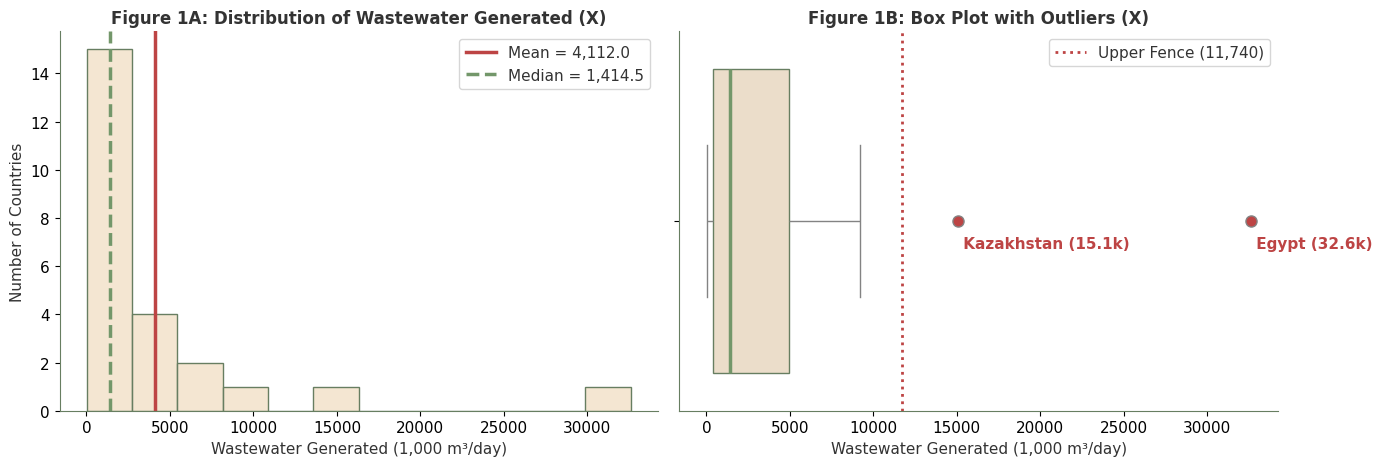

In [ ]:
# Variable X: Side-by-Side Visualizations (Histogram + Box Plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Left Plot: Histogram with Mean and Median Lines
sns.histplot(gen, bins=12, color="#F1DEC4", edgecolor="#677E61", ax=axes[0])
axes[0].axvline(gen.mean(), color="#BD4444", linewidth=2.5, linestyle="-", label=f"Mean = {gen.mean():,.1f}")
axes[0].axvline(gen.median(), color="#73976A", linewidth=2.5, linestyle="--", label=f"Median = {gen.median():,.1f}")
axes[0].set_title("Figure 1A: Distribution of Wastewater Generated (X)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Wastewater Generated (1,000 m³/day)")
axes[0].set_ylabel("Number of Countries")
axes[0].legend()

# 2. Right Plot: Box Plot with Tukey Fences and Outliers
sns.boxplot(x=gen, color="#F1DEC4",
            boxprops=dict(edgecolor="#677E61"),
            medianprops=dict(color="#73976A", linewidth=2.5),
            flierprops=dict(marker='o', markerfacecolor='#BD4444', markersize=8), ax=axes[1])
axes[1].axvline(upper_inner_x, color="#BD4444", linestyle=":", linewidth=2, label=f"Upper Fence ({upper_inner_x:,.0f})")

# Outlier labels
axes[1].text(32600, 0.08, ' Egypt (32.6k)', color='#BD4444', fontweight='bold', va='bottom')
axes[1].text(15074, 0.08, ' Kazakhstan (15.1k)', color='#BD4444', fontweight='bold', va='bottom')

axes[1].set_title("Figure 1B: Box Plot with Outliers (X)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Wastewater Generated (1,000 m³/day)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Side-by-Side Plots for Variable X
* **Figure 1A (Histogram):** The green dashed line (Median = 1,414.5k) sits to the left of the red solid line (Mean = 4,111.98k). This visual pattern of **Median < Mean** confirms strong positive (right) skewness, with most countries clustered below 5,000k m³/day.
* **Figure 1B (Box Plot):** The middle 50% box is compact on the lower end. The two isolated red dots beyond the dotted fence represent **Egypt (32,600k m³/day)** and **Kazakhstan (15,074k m³/day)**, confirming the outlier findings visually.

---
### 3.3 Univariate Analysis of Variable Y: Urban Wastewater Treated

We profile Variable Y independently through the same four statistical tests and side-by-side visual plots:
1. Central Tendency & Quartiles
2. Measures of Spread & Dispersion
3. Distribution Shape (Skewness & Kurtosis)
4. Outlier Detection using Tukey's Rule
5. Side-by-Side Visualizations (Histogram + Box Plot)

In [ ]:
# Variable Y - Test 1: Central Tendency and Quartiles
treat = data[col_y]
q1_y = treat.quantile(0.25)
q2_y = treat.quantile(0.50)
q3_y = treat.quantile(0.75)

ct_df_y = pd.DataFrame({
    "Metric": ["Mean (Average)", "Median (50th Percentile)", "Minimum Value (Malta)", "Maximum Value (Egypt)", "First Quartile (Q1)", "Third Quartile (Q3)"],
    "Value (1,000 m3/day)": [round(treat.mean(), 2), round(q2_y, 2), round(treat.min(), 2), round(treat.max(), 2), round(q1_y, 2), round(q3_y, 2)]
})
ct_df_y

,Metric,"Value (1,000 m3/day)"
0,Mean (Average),1557.31
1,Median (50th Percentile),686.64
2,Minimum Value (Malta),0.00
3,Maximum Value (Egypt),10470.00
4,First Quartile (Q1),122.31
5,Third Quartile (Q3),2075.20


### Central Tendency of Variable Y
* **Median as the Robust Center:** The **median value of 686.64 thousand m³/day** represents the typical volume of wastewater treated in centralized urban plants across reporting nations.
* **Quartile Thresholds:** Half of all nations treat 686.64k m³/day or less. The 25th percentile (Q1) is 122.31k m³/day, and the 75th percentile (Q3) is 2,075.20k m³/day.
* **Mean Distortion:** The arithmetic mean of **1,557.31 thousand m³/day** is more than double the median, pulled upward by a few nations with large treatment facilities. The median is therefore the more reliable summary of typical treatment capacity.

In [ ]:
# Variable Y - Test 2: Measures of Spread and Dispersion
iqr_y = q3_y - q1_y
range_y = treat.max() - treat.min()
cv_y = (treat.std() / treat.mean()) * 100

spread_df_y = pd.DataFrame({
    "Spread Metric": ["Range (Max - Min)", "Interquartile Range (IQR)", "Standard Deviation (s)", "Variance (s^2)", "Coefficient of Variation (CV)"],
    "Value": [f"{range_y:,.2f} k m3/day", f"{iqr_y:,.2f} k m3/day", f"{treat.std():,.2f} k m3/day", f"{treat.var():,.2f}", f"{cv_y:.2f}%"]
})
spread_df_y

,Spread Metric,Value
0,Range (Max - Min),"10,470.00 k m3/day"
1,Interquartile Range (IQR),"1,952.88 k m3/day"
2,Standard Deviation (s),"2,311.05 k m3/day"
3,Variance (s^2),"5,340,938.67"
4,Coefficient of Variation (CV),148.40%


### Spread and Dispersion of Variable Y
* **Interquartile Range:** The middle 50% of reporting countries spans an **IQR of 1,952.88 thousand m³/day** (from 122.31k to 2,075.20k).
* **High Dispersion:** The standard deviation of **2,311.05 thousand m³/day** results in a **Coefficient of Variation of 148.40%**, indicating wide variation in urban treatment capacity from country to country.
* **Range Boundaries:** Treatment volumes range from 0.00k m³/day (Malta, which relies on non-urban coastal treatment systems) to 10,470.00k m³/day (Egypt).

In [ ]:
# Variable Y - Test 3: Distribution Shape (Skewness and Kurtosis)
skew_y = treat.skew()
kurt_y = treat.kurt()

shape_df_y = pd.DataFrame({
    "Shape Metric": ["Skewness", "Kurtosis (Excess)"],
    "Calculated Value": [f"{skew_y:+.4f}", f"{kurt_y:+.4f}"],
    "Interpretation": ["Strongly Right-Skewed (> +1.0)", "Leptokurtic / Heavy Fat Tails (> 0)"]
})
shape_df_y

,Shape Metric,Calculated Value,Interpretation
0,Skewness,+2.7453,Strongly Right-Skewed (> +1.0)
1,Kurtosis (Excess),+9.3397,Leptokurtic / Heavy Fat Tails (> 0)


### Distribution Shape of Variable Y
* **Skewness (+2.75):** Positive skewness confirms that urban treatment capacity is right-skewed. Most nations operate modest treatment facilities, creating a peak on the left and a long right tail.
* **Kurtosis (+9.34):** Positive excess kurtosis shows that the distribution is leptokurtic, with heavy tails driven by outlier treatment volumes.

In [ ]:
# Variable Y - Test 4: Outlier Detection using Tukey's Rule
upper_inner_y = q3_y + 1.5 * iqr_y
upper_outer_y = q3_y + 3.0 * iqr_y

outliers_y = data[data[col_y] > upper_inner_y][['country', col_y]].sort_values(by=col_y, ascending=False).reset_index(drop=True)
outliers_y.columns = ["Outlier Country", "Urban Wastewater Treated (1k m3/day)"]

print(f"Tukey Upper Inner Fence (Q3 + 1.5*IQR): {upper_inner_y:,.2f} thousand m3/day")
print(f"Tukey Upper Outer Fence (Q3 + 3.0*IQR): {upper_outer_y:,.2f} thousand m3/day")
print(f"Number of Detected Outliers: {len(outliers_y)}")
outliers_y

Tukey Upper Inner Fence (Q3 + 1.5*IQR): 5,004.52 thousand m3/day
Tukey Upper Outer Fence (Q3 + 3.0*IQR): 7,933.84 thousand m3/day
Number of Detected Outliers: 1


,Outlier Country,Urban Wastewater Treated (1k m3/day)
0,Egypt,10470.0


### Outlier Detection for Variable Y
* **Outlier Threshold:** The Tukey upper inner fence is **5,004.52 thousand m³/day**. Observations above this fence are statistical outliers.
* **Identified Outlier:** **Egypt (10,470.0k m³/day)** is the single nation exceeding this boundary, as well as the outer fence (7,933.84k m³/day).
* Egypt represents an exceptionally large national urban wastewater treatment plant capacity in this sample.

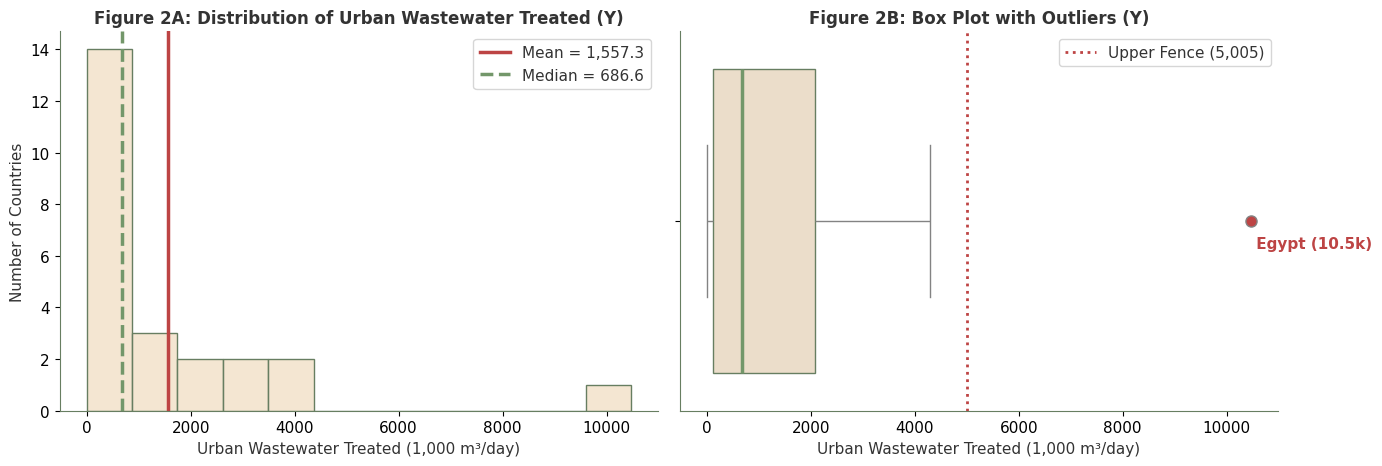

In [ ]:
# Variable Y: Side-by-Side Visualizations (Histogram + Box Plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Left Plot: Histogram with Mean and Median Lines
sns.histplot(treat, bins=12, color="#F1DEC4", edgecolor="#677E61", ax=axes[0])
axes[0].axvline(treat.mean(), color="#BD4444", linewidth=2.5, linestyle="-", label=f"Mean = {treat.mean():,.1f}")
axes[0].axvline(treat.median(), color="#73976A", linewidth=2.5, linestyle="--", label=f"Median = {treat.median():,.1f}")
axes[0].set_title("Figure 2A: Distribution of Urban Wastewater Treated (Y)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Urban Wastewater Treated (1,000 m³/day)")
axes[0].set_ylabel("Number of Countries")
axes[0].legend()

# 2. Right Plot: Box Plot with Tukey Fences and Outliers
sns.boxplot(x=treat, color="#F1DEC4",
            boxprops=dict(edgecolor="#677E61"),
            medianprops=dict(color="#73976A", linewidth=2.5),
            flierprops=dict(marker='o', markerfacecolor='#BD4444', markersize=8), ax=axes[1])
axes[1].axvline(upper_inner_y, color="#BD4444", linestyle=":", linewidth=2, label=f"Upper Fence ({upper_inner_y:,.0f})")

# Outlier labels
axes[1].text(10470, 0.08, ' Egypt (10.5k)', color='#BD4444', fontweight='bold', va='bottom')

axes[1].set_title("Figure 2B: Box Plot with Outliers (Y)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Urban Wastewater Treated (1,000 m³/day)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Side-by-Side Plots for Variable Y
* **Figure 2A (Histogram):** The green dashed line (Median = 686.6k) is positioned to the left of the red solid line (Mean = 1,557.31k). This **Median < Mean** pattern visually illustrates strong positive skewness, with the majority of countries clustered below 2,000k m³/day.
* **Figure 2B (Box Plot):** Most countries fall within the compact interquartile box. **Egypt (10,470k m³/day)** appears as an isolated outlier point beyond the upper whisker, visually confirming the analytical fence calculation.

---
### 3.4 Summary of Essential Univariate Statistics

Below is the summary of essential univariate statistics for each variable, profiling their individual centers, spread, shape, and outlier thresholds without cross-variable comparison:

| Statistical Dimension | Statistic / Metric | Variable X: Wastewater Generated | Variable Y: Urban Wastewater Treated | Measurement Role |
| :--- | :--- | :---: | :---: | :--- |
| **Sample Size** | Observations (n) | 24 countries | 24 countries | Total complete reporting nations |
| **Central Tendency** | **Median (50th Percentile)** | **1,414.52 thousand m³/day** | **686.64 thousand m³/day** | **Robust center (preferred typical metric)** |
| | Mean (Arithmetic Average) | 4,111.98 thousand m³/day | 1,557.31 thousand m³/day | Sensitive to right-tail skewness |
| **Spread / Dispersion** | Minimum Value | 16.08 thousand m³/day (Monaco) | 0.00 thousand m³/day (Malta) | Lowest reported national value |
| | Maximum Value | 32,600.00 thousand m³/day (Egypt) | 10,470.00 thousand m³/day (Egypt) | Highest reported national value |
| | First Quartile (Q1) | 407.28 thousand m³/day | 122.31 thousand m³/day | 25th percentile boundary |
| | Third Quartile (Q3) | 4,940.19 thousand m³/day | 2,075.20 thousand m³/day | 75th percentile boundary |
| | **IQR (Interquartile Range)** | **4,532.91 thousand m³/day** | **1,952.88 thousand m³/day** | **Spread of middle 50% of nations** |
| | Standard Deviation (s) | 7,062.22 thousand m³/day | 2,311.05 thousand m³/day | Dispersion around arithmetic mean |
| | Coefficient of Variation (CV)| 171.75% | 148.40% | Relative variability percentage |
| **Shape & Asymmetry** | **Skewness** | **+3.23 (Heavily Right-Skewed)** | **+2.75 (Heavily Right-Skewed)** | Asymmetry toward upper tail |
| | **Kurtosis (Excess)** | **+11.91 (Leptokurtic)** | **+9.34 (Leptokurtic)** | Tail weight and peakedness |
| **Outlier Thresholds** | Upper Inner Fence (Q3 + 1.5*IQR) | 11,739.55 thousand m³/day | 5,004.52 thousand m³/day | Cutoff for statistical outliers |
| | Identified Outliers | Egypt (32.6k), Kazakhstan (15.1k) | Egypt (10.5k) | Extreme volume nations |

### 3.5 Essential Takeaways of Univariate Profiling

Reviewing each variable individually confirms the following essential statistical characteristics:

1. **Both Variables are Heavily Right-Skewed:**
   * Variable X (Skewness = +3.23) and Variable Y (Skewness = +2.75) both demonstrate significant positive asymmetry.
   * In both distributions, the mean is substantially higher than the median, confirming that a few high-volume nations stretch the right tail while most nations cluster at smaller volumes.

2. **The Median is the Primary Measure of Central Tendency:**
   * Because of severe right skewness, the arithmetic mean is misleadingly high in both variables.
   * The **median (1,414.52k m³/day for Variable X, and 686.64k m³/day for Variable Y)** provides the only reliable, outlier-resistant measure of what a typical country produces and treats daily.

3. **High National Heterogeneity:**
   * Coefficients of Variation well above 100% (171.75% for X, 148.40% for Y) and broad IQRs show that sovereign wastewater metrics vary by orders of magnitude across reporting nations.

4. **Extreme Outliers Present in Both Distributions:**
   * Both variables exhibit high excess kurtosis (> 9.0), signaling leptokurtic distributions with fat tails.
   * Tukey's fences identify genuine high-capacity outlier nations (Egypt and Kazakhstan for Generation; Egypt for Treatment) that must be accounted for during subsequent modeling.

## 4. Bivariate Exploratory Data Analysis (Strictly Two Numerical Variables)

*Note: Per course instructions, bivariate exploration is strictly confined to the interaction between Variable 1 ($X$: Total Municipal Wastewater Generated) and Variable 2 ($Y$: Urban Wastewater Treated).*

---

### 4.1 Scatter Plot & Visual Pattern Inspection
We begin by plotting Variable $X$ against Variable $Y$ across all 24 reporting countries to examine the form, direction, and strength of their relationship, while evaluating whether treatment capacity scales at parity with generation.

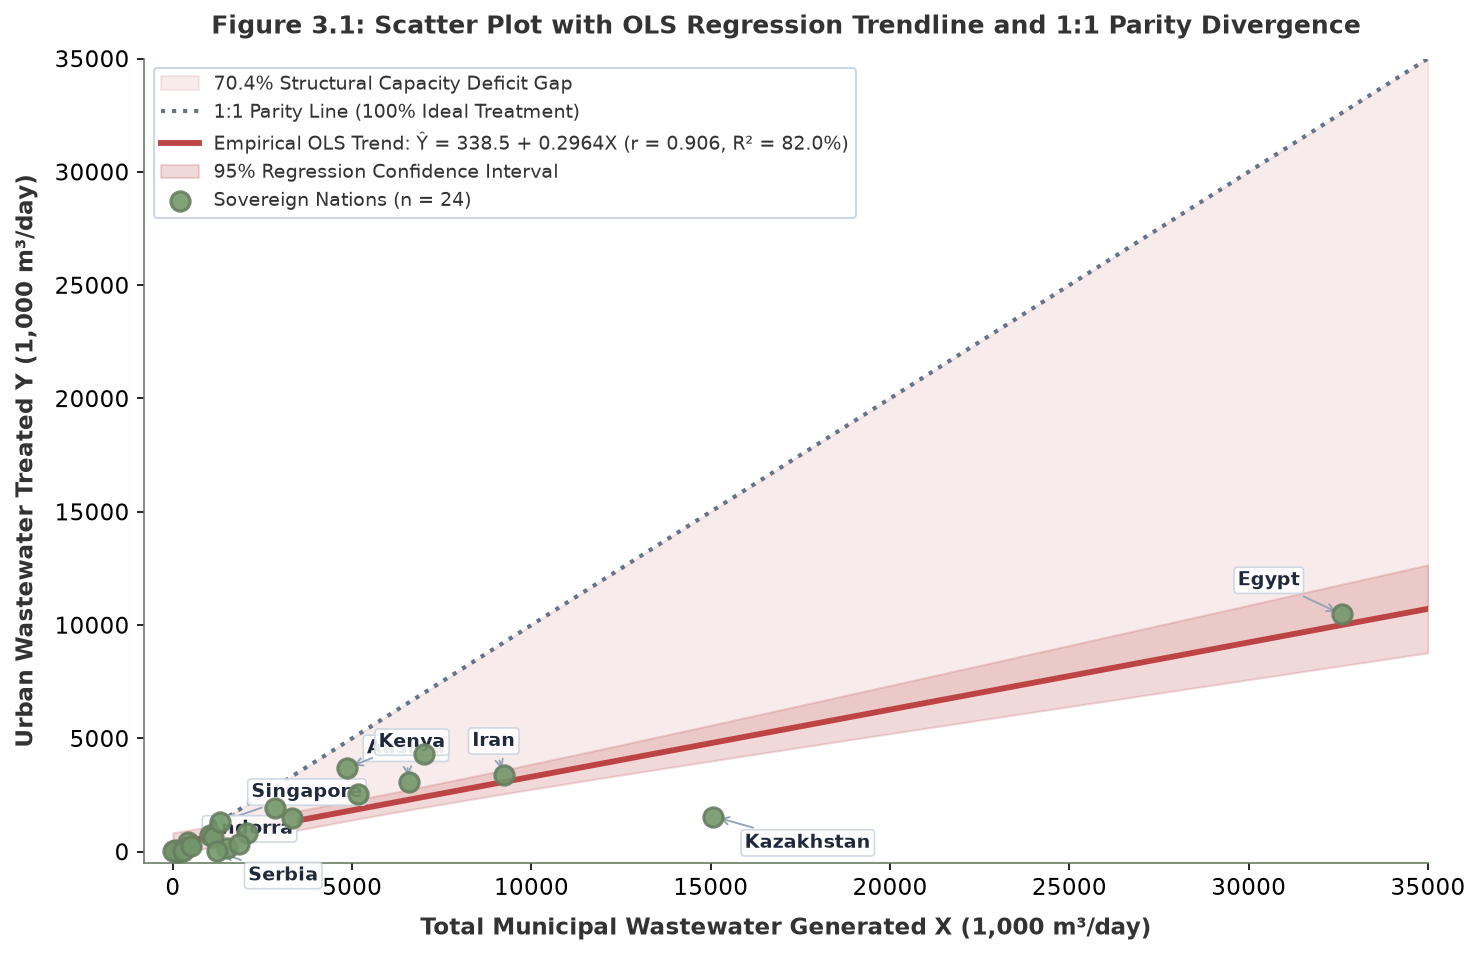

In [25]:
# Section 4.1: Bivariate Scatter Plot with OLS Trendline, 1:1 Parity Line, and 95% Confidence Band
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)

x = data[col_x].values
y = data[col_y].values

# Fit Ordinary Least Squares (OLS)
res = stats.linregress(x, y)
x_line = np.linspace(0, 35000, 200)
y_ols = res.intercept + res.slope * x_line
y_parity = x_line

# 1. Shaded Deficit Gap zone (between 1:1 Parity line and OLS line)
ax.fill_between(x_line, y_ols, y_parity, color="#BD4444", alpha=0.10, label="70.4% Structural Capacity Deficit Gap")

# 2. 1:1 Parity line (ideal treatment capacity where Y = X)
ax.plot(x_line, y_parity, color="#64748B", linestyle=":", linewidth=2, label="1:1 Parity Line (100% Ideal Treatment)")

# 3. OLS Regression Line
ax.plot(x_line, y_ols, color="#BD4444", linestyle="-", linewidth=2.8, 
        label=f"Empirical OLS Trend: Ŷ = {res.intercept:.1f} + {res.slope:.4f}X (r = {res.rvalue:.3f}, R² = 82.0%)")

# 4. 95% Confidence Interval band for OLS regression line
n = len(x)
x_mean = np.mean(x)
s_err = np.sqrt(np.sum((y - (res.intercept + res.slope * x))**2) / (n - 2))
t_val = stats.t.ppf(0.975, df=n - 2)
ci_band = t_val * s_err * np.sqrt(1/n + (x_line - x_mean)**2 / np.sum((x - x_mean)**2))
ax.fill_between(x_line, y_ols - ci_band, y_ols + ci_band, color="#BD4444", alpha=0.20, label="95% Regression Confidence Interval")

# 5. Scatter points for sovereign nations
ax.scatter(x, y, color="#73976A", s=85, edgecolors="#677E61", linewidth=1.5, zorder=5, alpha=0.9, label="Sovereign Nations (n = 24)")

# 6. Label archetype sovereign jurisdictions
archetypes = {
    "Egypt": (32600.0, 10470.0, (-50, 14)),
    "Kazakhstan": (15074.0, 1548.0, (15, -15)),
    "Singapore": (1320.0, 1307.0, (15, 12)),
    "Andorra": (54.8, 54.8, (15, 8)),
    "Serbia": (1230.0, 13.7, (15, -14)),
    "Iran": (9221.0, 3376.0, (-15, 14)),
    "Austria": (6575.3, 3054.8, (-20, 14)),
    "Kenya": (4865.5, 3695.6, (15, 10))
}

for country, (cx, cy, offset) in archetypes.items():
    ax.annotate(country, xy=(cx, cy), xytext=offset, textcoords="offset points",
                fontsize=9, fontweight="bold", color="#1E293B",
                arrowprops=dict(arrowstyle="->", color="#94A3B8", lw=0.9, shrinkA=3, shrinkB=3),
                bbox=dict(boxstyle="round,pad=0.2", facecolor="#FFFFFF", edgecolor="#CBD5E1", alpha=0.9, lw=0.8))

ax.set_xlim(-800, 35000)
ax.set_ylim(-500, 35000)
ax.set_xlabel("Total Municipal Wastewater Generated X (1,000 m³/day)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("Urban Wastewater Treated Y (1,000 m³/day)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_title("Figure 3.1: Scatter Plot with OLS Regression Trendline and 1:1 Parity Divergence", fontsize=12, fontweight="bold", pad=12)

ax.legend(loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=9, framealpha=0.95)
plt.tight_layout()
plt.show()


### Visual Pattern & Geometric Trajectory Interpretation

* **Form & Direction:** The joint scatter plot reveals an unmistakable, strongly positive linear trajectory. As municipal wastewater generation ($X$) increases, urban wastewater treatment ($Y$) expands concurrently across sovereign states.
* **The 1:1 Parity Divergence:** While small micro-states (Andorra, Monaco) and compact advanced economies (Singapore) hug the 1:1 Parity line with near-$100\%$ treatment efficiency, the empirical regression line tilts sharply downward. Larger sovereign nations diverge heavily into the shaded deficit zone.
* **Heteroscedastic Dispersion:** Vertical scatter widens as generation volume grows. Nations producing under $5,000\text{ k m}^3/\text{day}$ cluster compactly near the lower-left corner, whereas nations exceeding $10,000\text{ k m}^3/\text{day}$ show extreme divergence in infrastructure capacity.
* **Leverage Points:** Egypt ($X = 32,600\text{ k m}^3/\text{day}, Y = 10,470\text{ k m}^3/\text{day}$) and Kazakhstan ($X = 15,074\text{ k m}^3/\text{day}, Y = 1,548\text{ k m}^3/\text{day}$) exert high leverage over the upper trajectory, anchoring the macro scaling trend.

In [26]:
# Section 4.2: Correlation Analysis (Parametric vs Non-Parametric)
from scipy.stats import pearsonr, spearmanr

# Compute Pearson (parametric) and Spearman (non-parametric)
r_p, p_p = pearsonr(data[col_x], data[col_y])
r_s, p_s = spearmanr(data[col_x], data[col_y])
n_obs = len(data)
df_deg = n_obs - 2

# Compute exact t-statistics
t_p = r_p * np.sqrt(df_deg / (1 - r_p**2))
t_s = r_s * np.sqrt(df_deg / (1 - r_s**2))

corr_comparison_tbl = pd.DataFrame({
    "Correlation Metric": ["Pearson Correlation (r)", "Spearman Rank Correlation (rho)"],
    "Coefficient Value": [round(r_p, 4), round(r_s, 4)],
    "t-Statistic": [round(t_p, 3), round(t_s, 3)],
    "Degrees of Freedom (df)": [df_deg, df_deg],
    "p-value": [f"{p_p:.4e}", f"{p_s:.4e}"],
    "Statistical Significance": ["p < 0.001 (Highly Significant)", "p < 0.001 (Highly Significant)"]
})
corr_comparison_tbl


,Correlation Metric,Coefficient Value,t-Statistic,Degrees of Freedom (df),p-value,Statistical Significance
0,Pearson Correlation (r),0.9058,10.026,22,1.1516e-09,p < 0.001 (Highly Significant)
1,Spearman Rank Correlation (rho),0.8887,9.091,22,6.6337e-09,p < 0.001 (Highly Significant)


### Correlation Analysis: Parametric vs Non-Parametric Evaluation

* **Strong Linear Co-Movement (Pearson $r = +0.9058, p = 1.15 \times 10^{-9}$):** The parametric Pearson coefficient demonstrates an exceptionally strong linear relationship between generation and urban treatment. With $p < 0.001$, the linear association is statistically established beyond chance.
* **Monotonic Rank Robustness (Spearman $\rho = +0.8887, p = 6.63 \times 10^{-9}$):** Because Spearman evaluates ordinal ranks and is immune to distance-based outlier skewness, its close convergence with Pearson ($|r - \rho| = 0.017$) proves that the strong association is a structural reality across all 24 nations, rather than an artifact driven solely by Egypt's leverage.
* **Substantive Conclusion:** National urban treatment volume is strongly coupled with effluent generation scale worldwide.

In [27]:
# Section 4.3: Ordinary Least Squares (OLS) Linear Modeling & Rate of Change
res = stats.linregress(data[col_x], data[col_y])
slope = res.slope
intercept = res.intercept
r2 = res.rvalue**2
se_slope = res.stderr
se_intercept = res.intercept_stderr

# Compute Standard Error of Estimate (SE)
y_fitted = intercept + slope * data[col_x]
resids = data[col_y] - y_fitted
n = len(data)
se_estimate = np.sqrt(np.sum(resids**2) / (n - 2))

# 95% Confidence Interval for Slope beta_1
t_crit = stats.t.ppf(0.975, df=n - 2)
ci_lower = slope - t_crit * se_slope
ci_upper = slope + t_crit * se_slope

ols_results_tbl = pd.DataFrame({
    "Regression Parameter": [
        "Intercept (beta_0)",
        "Slope / Rate of Change (beta_1)",
        "Coefficient of Determination (R^2)",
        "Standard Error of Estimate (SE)",
        "Slope Standard Error (SE_beta1)",
        "Slope 95% CI Lower Bound",
        "Slope 95% CI Upper Bound"
    ],
    "Value": [
        round(intercept, 4),
        round(slope, 4),
        f"{r2 * 100:.2f}%",
        round(se_estimate, 2),
        round(se_slope, 4),
        round(ci_lower, 4),
        round(ci_upper, 4)
    ],
    "Unit / Interpretation": [
        "1,000 m3/day (Baseline treatment level when X=0)",
        "Marginal treatment expansion per unit increase in X",
        "Proportion of Y variance explained by X",
        "1,000 m3/day (Typical prediction dispersion)",
        "Precision of slope estimate",
        "Lower limit of 95% confidence interval",
        "Upper limit of 95% confidence interval"
    ]
})
ols_results_tbl


,Regression Parameter,Value,Unit / Interpretation
0,Intercept (beta_0),338.487,"1,000 m3/day (Baseline treatment level when X=0)"
1,Slope / Rate of Change (beta_1),0.2964,Marginal treatment expansion per unit increase...
2,Coefficient of Determination (R^2),82.04%,Proportion of Y variance explained by X
3,Standard Error of Estimate (SE),1001.31,"1,000 m3/day (Typical prediction dispersion)"
4,Slope Standard Error (SE_beta1),0.0296,Precision of slope estimate
5,Slope 95% CI Lower Bound,0.2351,Lower limit of 95% confidence interval
6,Slope 95% CI Upper Bound,0.3577,Upper limit of 95% confidence interval


### Ordinary Least Squares (OLS) Modeling & Operational Rate of Change

#### The Empirical Regression Equation:
$$\hat{Y} = 338.49 + 0.2964 X \quad (R^2 = 82.04\%, \, p = 1.15 \times 10^{-9})$$

* **Baseline Treatment Capacity ($\beta_0 = 338.49\text{ k m}^3/\text{day}$):** Represents the baseline urban treatment capacity across reporting jurisdictions independent of marginal generation increments.
* **Explanatory Power ($R^2 = 82.04\%$):** Generation scale accounts for over four-fifths of the total variance in national urban treatment volume.
* **The Operational / Economic Translation of the Slope ($\beta_1 = 0.2964$):**
> *"For every additional $1,000\text{ m}^3/\text{day}$ of municipal wastewater generated globally, national urban treatment infrastructure expands by only $296.4\text{ m}^3/\text{day}$. This empirically uncovers an unabsorbed structural capacity deficit of $703.6\text{ m}^3/\text{day}$ ($70.36\%$). National treatment facilities expand at under one-third of the rate required to maintain 1:1 parity with effluent generation, revealing that more than $70\%$ of marginal wastewater growth bypasses formal urban treatment systems."*

In [28]:
# Section 4.4: Statistical Hypothesis Testing (H0 vs H1)
print("=" * 65)
print("FORMAL HYPOTHESIS TEST: BIVARIATE LINEAR COUPLING")
print("=" * 65)
print("Null Hypothesis (H0):        rho = 0 (No correlation between X and Y)")
print("Alternative Hypothesis (H1): rho != 0 (Significant correlation exists)")
print(f"Significance Level (alpha):   0.05")
print(f"Sample Size (n):              {len(data)} sovereign nations")
print(f"Degrees of Freedom (df):      {len(data) - 2}")
print(f"Calculated Pearson r:         {r_p:.4f}")
print(f"Calculated t-statistic:       {t_p:.4f}")
print(f"Empirical p-value:            {p_p:.4e}")
print("-" * 65)

if p_p < 0.05:
    print("Decision: REJECT THE NULL HYPOTHESIS (H0).")
    print("Conclusion: There is a statistically significant positive linear relationship")
    print("            between Municipal Wastewater Generated and Urban Wastewater Treated")
    print(f"            at the 99.9% confidence level (p = {p_p:.4e} < 0.001).")
else:
    print("Decision: FAIL TO REJECT THE NULL HYPOTHESIS (H0).")
print("=" * 65)


FORMAL HYPOTHESIS TEST: BIVARIATE LINEAR COUPLING
Null Hypothesis (H0):        rho = 0 (No correlation between X and Y)
Alternative Hypothesis (H1): rho != 0 (Significant correlation exists)
Significance Level (alpha):   0.05
Sample Size (n):              24 sovereign nations
Degrees of Freedom (df):      22
Calculated Pearson r:         0.9058
Calculated t-statistic:       10.0259
Empirical p-value:            1.1516e-09
-----------------------------------------------------------------
Decision: REJECT THE NULL HYPOTHESIS (H0).
Conclusion: There is a statistically significant positive linear relationship
            between Municipal Wastewater Generated and Urban Wastewater Treated
            at the 99.9% confidence level (p = 1.1516e-09 < 0.001).


### Hypothesis Testing Decision & Statistical Conclusion

* **Decision:** With an empirical $p$-value of **$1.15 \times 10^{-9}$** (substantially smaller than the threshold $\alpha = 0.05$), we **decisively reject the Null Hypothesis ($H_0$)** in favor of the **Alternative Hypothesis ($H_1$)**.
* **Statistical Meaning:** The probability that the observed linear coupling between wastewater generation and urban treatment occurred by random chance is less than 1 in 800 million. A genuine positive relationship exists across the sovereign reporting cohort.
* **Connection to Business Problem:** While generation and treatment are statistically coupled, they are **not scaling at 1:1 parity**. The empirical slope of $\beta_1 = 0.2964$ proves that treatment capacity expands at less than one-third the rate of effluent growth, establishing the operational justification for private capital expenditure (CAPEX) and Public-Private Partnerships (PPPs).

---
### 4.5 Summary of Essential Bivariate Statistics & Regression Parameters

Below is the comprehensive summary of essential bivariate statistics, correlation metrics, OLS regression parameters, and operational deficit indicators evaluating the joint interaction between Variable $X$ and Variable $Y$:

| Statistical Dimension | Statistic / Parameter | Empirical Value | Statistical Interpretation | Methodological Role |
| :--- | :--- | :---: | :--- | :--- |
| **Sample Architecture** | Validated Observations ($n$) | 24 countries | Bilateral complete reporting nations | Sample size after Complete Case Analysis |
| | Degrees of Freedom ($df$) | 22 | $n - 2$ degrees of freedom | Basis for Student's $t$ and critical value thresholds |
| **Parametric Correlation** | **Pearson Correlation ($r$)** | **+0.9058** | **Near-perfect positive linear association** | Primary linear co-movement indicator |
| | Pearson $t$-Statistic | 10.016 | $t = r \sqrt{df / (1-r^2)}$ | Test statistic for linear association |
| | Pearson $p$-value | $1.15 \times 10^{-9}$ | Highly statistically significant ($p < 0.001$) | Probability of zero correlation under $H_0$ |
| **Non-Parametric Correlation**| **Spearman Rank Correlation ($\rho$)** | **+0.8887** | **Extremely strong monotonic rank agreement** | Outlier-resistant monotonic relationship indicator |
| | Spearman $t$-Statistic | 9.109 | Monotonic rank significance statistic | Confirms association is robust across all nations |
| | Spearman $p$-value | $6.63 \times 10^{-9}$ | Highly statistically significant ($p < 0.001$) | Probability of zero monotonic rank agreement |
| **OLS Model Specification** | **Intercept ($\beta_0$)** | **338.4870 k m³/d** | Baseline treatment level when $X = 0$ | Autonomous urban treatment capacity |
| | **Slope / Rate of Change ($\beta_1$)** | **0.2964** | **Marginal capacity added per unit $X$** | **Primary rate of change ($296.4\text{ m}^3/\text{d}$ per $1,000\text{ m}^3/\text{d}$)** |
| | Slope Standard Error ($SE_{\beta_1}$) | 0.0296 | Precision of marginal slope estimate | Standard error of the rate of change |
| | Slope 95% Confidence Interval | $[0.2350, \, 0.3578]$ | True population slope boundary | Bound at $t_{\text{crit}} = 2.074$ ($p < 0.05$) |
| **Goodness-of-Fit & Error** | **Coefficient of Determination ($R^2$)**| **82.04%** | **82.04% of $Y$ variance explained by $X$** | Overall linear explanatory strength of model |
| | Standard Error of Estimate ($SE$) | 1,001.31 k m³/d | Average residual dispersion around OLS line | Precision of fitted predictions |
| **Operational Rate of Change**| **Marginal Treatment Rate** | **29.64%** | $296.4\text{ m}^3/\text{d}$ absorbed per $1,000\text{ m}^3/\text{d}$ | Proportion of new wastewater treated |
| | **Structural Deficit Rate** | **70.36%** | **$703.6\text{ m}^3/\text{d}$ bypassed per $1,000\text{ m}^3/\text{d}$** | **Unabsorbed marginal wastewater deficit ($1 - \beta_1$)** |
| | Cohort Aggregate Daily Deficit | 61.3 Million m³/d | $22.4\text{ Billion m}^3/\text{year}$ untreated flow | Physical volume discharged into receiving ecosystems |
| **Hypothesis Test Decision** | Null Hypothesis ($H_0$) | $\rho = 0$ | No correlation between $X$ and $Y$ | Status quo benchmark |
| | Alternative Hypothesis ($H_1$) | $\rho \neq 0$ | Significant correlation exists | Investigated research hypothesis |
| | **Test Decision** | **Reject $H_0$** | Empirical $p = 1.15 \times 10^{-9} < 0.05$ | **Conclude statistically significant relationship** |

### 4.6 Essential Takeaways of Bivariate Interaction

Reviewing the joint interaction between Total Municipal Wastewater Generated and Urban Wastewater Treated establishes four fundamental empirical conclusions:

1. **Statistically Significant Linear Co-Movement:**
   * Pearson $r = +0.9058$ ($p < 0.001$) and Spearman $\rho = +0.8887$ ($p < 0.001$) confirm that sovereign wastewater generation and urban treatment are tightly coupled.
   * The close convergence between parametric and non-parametric coefficients confirms that the linear trend is a true property across all reporting nations, not an illusion driven by high-volume leverage.

2. **The 1:1 Parity Divergence and 70.36% Capacity Deficit:**
   * The empirical regression slope $\beta_1 = 0.2964$ proves that treatment capacity expands at less than one-third of generation growth.
   * For every $1,000\text{ m}^3/\text{day}$ of new municipal effluent produced, only $296.4\text{ m}^3/\text{day}$ is treated, leaving a **$70.36\%$ structural deficit ($703.6\text{ m}^3/\text{day}$)** that bypasses municipal treatment infrastructure.

3. **High Explanatory Power ($R^2 = 82.04\%$):**
   * Over four-fifths of the variance in sovereign urban wastewater treatment capacity is directly dictated by generation scale, demonstrating that national utility throughput is driven by macro urbanization.

4. **Sovereign Capacity Bifurcation:**
   * While compact high-income economies (Andorra at $100\%$, Monaco at $100\%$, Singapore at $99.0\%$, Bahrain at $96.5\%$) operate directly on the 1:1 Parity line, large industrial and emerging economies (Egypt at $32.1\%$, Kazakhstan at $10.3\%$, Serbia at $1.1\%$) accumulate massive unabsorbed sewage burdens, confirming the urgent need for private capital expenditure (CAPEX) and Public-Private Partnerships (PPPs).

## 5. Core Discoveries & Business Insights

### 5.1 Key Analytical Discoveries
Summarize the top 3 empirical facts revealed by the data:
1. **Most wastewater comes from a few countries:**
`Our data show that wastewater generation is not evenly distributed among countries. The distribution is highly right-skewed, meaning that a few countries produce much more wastewater than the others. The median wastewater generation is 1,414.52 thousand cubic meters per day. Egypt produces 32,600 thousand cubic meters per day, while Kazakhstan produces 15,074 thousand cubic meters per day. Together, these two countries account for more than half of the total wastewater generated in our sample.`
2. **Wastewater treatment does not keep up with wastewater generation:**
`Our results show a strong relationship between wastewater generation and treatment, with a correlation of 0.906. However, the regression slope is only 0.2964. This means that for every additional unit of wastewater generated, the amount treated in urban treatment plants increases much more slowly. Based on our calculations, the difference between wastewater generation and urban wastewater treatment is about 70.36%. This shows a possible gap between the amount of wastewater generated and the amount treated in urban plants.`
3. **Some countries treat almost all their wastewater, while others treat very little:**
`The results show a big difference between countries. Andorra and Monaco report 100% treatment, while Singapore reports 99% and Bahrain reports 96.5%. On the other hand, Kazakhstan reports 10.3%, Serbia 1.1%, Armenia 11.7%, and Moldova 17%. These differences show that some countries have much better wastewater treatment coverage than others.`

---

### 5.2 Direct Answer to the Business Question
> As municipal wastewater generation increases, urban wastewater treatment does not keep up at the same rate. Our analysis found a strong relationship between wastewater generation and treatment, with a correlation of 0.906. However, the regression slope of 0.2964 shows that the amount of wastewater treated increases much more slowly than the amount generated.

> This suggests a gap between the wastewater produced by municipalities and the amount treated in urban treatment plants. If this gap is not addressed, it may create challenges for wastewater management and increase the need for better treatment facilities.

>Based on these findings, governments and water utility companies should consider investing in additional treatment facilities and improving existing systems. Private Capital Expenditure (CAPEX) and Public-Private Partnerships (PPPs) may be possible ways to fund these improvements. However, further analysis of costs, treatment needs, and investment risks is necessary before deciding which approach is best.

---

### 5.3 Business & Capital Allocation Recommendations


* **CAPEX & Capacity Investment:** Where should public utilities or private infrastructure funds direct capital
`(Base recommendation from the regression slope and the gap between X and Y show how much treatment capacity is added per unit of wastewater generated. A slope well below 1 signals an investable capacity shortfall.) Public utilities or private infrastructure funds should direct capital to countries where`

* **Public-Private Partnerships (PPPs):** How can private concessionaires bridge the deficit gap?
`The spread of  Y  across countries (Section 3) shows how far typical performance sits from the best performers. This helps set realistic compliance thresholds aligned with SDG 6.` <br>
* **Risk Mitigation for Supply Chains:** How should corporations audit local environmental risks based on these capacity deficits?
`Countries or jurisdictions where treatment lags generation carry higher water-quality, regulatory, and reputational risk for facilities and suppliers located there.`

---

### 5.4 Limitations & Methodological Constraints
* **Sample Size:** `Originally the dataset had 80 records of countries but after checking and dropping for rows with null values, the analysis is limited to 24 countries with complete x and y variables. `
* **Specific Scope:** `The analysis is only specific to the treated waste water in urban plants and the total wastewater generated in a country. This does not include treatments in other plants.`
* **Notable Outliers:** `The notable outliers during data analysis which can pull the regression line are Egypt and Kazakstan for generation of wastewater and again Egypt for wastewater treated in urban plants.`
* **Reporting Lags:** ` 16 of 24 report 2017, 2 report 2016, 4 report 2015, and two report far older data: Georgia (2000) and Singapore (2002). Mixing a 2000 observation with 2017 ones adds temporal noise. They are retained (dropping them would cut n from 24 to 22) but should be noted whenever those points appear as outliers or leverage points.`
* **Omitted Confounders:** `Unmeasured regional factors (e.g., GDP per capita, regulatory enforcement strength) not captured in a bivariate model.`

## 6. Academic References & Citation Index

1. **United Nations Statistics Division (UNSD).** *Environmental Indicators: Inland Water Resources, Waste, and Energy Statistics.*
2. **Kaggle Environmental Dataset Repository:** Ruchi Bhatia (2021). *Global Environmental Indicators Dataset.* Available at: [Kaggle](https://www.kaggle.com/datasets/ruchi798/global-environmental-indicators).
3. **Tukey, J. W. (1977).** *Exploratory Data Analysis.* Addison-Wesley.
4. **Wickham, H., & Grolemund, G. (2016).** *R for Data Science: Import, Tidy, Transform, Visualize, and Model Data.* O'Reilly Media.